# 07. Многоклассовая классификация банковских рисков: сравнение моделей

**Экспериментальная часть дипломного проекта.** Сопоставление TF-IDF + Logistic Regression / LinearSVC с дообученной `microsoft/mdeberta-v3-base` в задаче классификации новостей на четыре класса: `no_risk`, `cyber_risk`, `operational_risk`, `regulatory_risk`.

- **Основная метрика:** Macro F1 на фиксированной валидационной выборке.
- **Дополнительные метрики:** Risk Macro F1 (среднее по трём риск-классам), F1 каждого класса, Precision, Recall, матрица ошибок.
- **Выбор модели:** лучшая конфигурация в пределах каждого семейства по validation Macro F1.
- **Назначение ноутбука:** повторно вычислить доступные метрики и проанализировать сохранённые результаты **без обучения и без использования test**.

В таблицах используются реальные файлы, выгруженные из Kaggle и локального baseline. Числа других запусков считываются из сохранённых отчётов; **среди нейросетевых конфигураций пообъектные предсказания доступны только для лучшей mDeBERTa**, поэтому здесь независимо пересчитываются её метрики и матрица ошибок. Прогнозы всех четырёх классических конфигураций сохранены отдельно в `results/multiclass/baseline/*_valid_predictions.csv`.

## 1. Входные данные и проверка происхождения результатов

Анализ использует локальные файлы проекта без загрузки моделей. 

| Относительный путь | Назначение |
|---|---|
| `data/bank_risk_dataset.csv` | Исходный неизменённый датасет |
| `results/multiclass/baseline/validation_comparison.csv` | Метрики 4 конфигураций классического ML |
| `results/multiclass/dl/validation_comparison.csv` | Метрики 3 конфигураций mDeBERTa |
| `results/multiclass/dl/selection.json` | Зафиксированный выбор нейросети |
| `results/multiclass/dl/valid_predictions.csv` | Истинные метки, прогнозы и logits выбранной mDeBERTa на validation |

In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, f1_score, accuracy_score)
from IPython.display import display

CLASSES = ['no_risk', 'cyber_risk', 'operational_risk', 'regulatory_risk']
LABELS = {'no_risk':'Нет риска', 'cyber_risk':'Киберриск',
          'operational_risk':'Операционный риск', 'regulatory_risk':'Регуляторный риск'}

def has_all_inputs(p):
    return all((p / relative).is_file() for relative in [
        'data/bank_risk_dataset.csv',
        'results/multiclass/baseline/validation_comparison.csv',
        'results/multiclass/dl/validation_comparison.csv',
        'results/multiclass/dl/valid_predictions.csv',
        'results/multiclass/dl/selection.json'])

cwd = Path.cwd().resolve()
search_roots = [cwd, cwd.parent] + [p for p in cwd.iterdir() if p.is_dir()]
ROOT = next((p for p in search_roots if has_all_inputs(p)), None)
if ROOT is None:
    raise FileNotFoundError('В рабочем каталоге проекта необходимы папки data/ и results/ с исходными файлами.')
print('Корень проекта:', ROOT)

DATA_DIR = ROOT / 'data'
BASE_DIR = ROOT / 'results' / 'multiclass'
dataset_path = DATA_DIR / 'bank_risk_dataset.csv'
dataset_sha = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
df = pd.read_csv(dataset_path)
base = pd.read_csv(BASE_DIR / 'baseline' / 'validation_comparison.csv')
dl = pd.read_csv(BASE_DIR / 'dl' / 'validation_comparison.csv')
selection = json.loads((BASE_DIR / 'dl' / 'selection.json').read_text(encoding='utf-8'))
pred = pd.read_csv(BASE_DIR / 'dl' / 'valid_predictions.csv')

assert all(dataset_sha == h for h in pd.concat([base['dataset_sha256'],dl['dataset_sha256']]))
assert dataset_sha == selection['dataset_sha256']
assert set(df['split']) == {'train','valid','test'}
assert set(df['risk_type_4cls']) == set(CLASSES)
assert df['sample_id'].is_unique
print('SHA-256 датасета:', dataset_sha)
print('Файлы: baseline —',len(base),'конфигурации; Deep Learning —',len(dl),'конфигурации')

Корень проекта: D:\bank_risk_diploma_final_multiclass_2026_10_25\_review_execution
SHA-256 датасета: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3
Файлы: baseline — 4 конфигурации; Deep Learning — 3 конфигурации


## 2. Постановка задачи и дисбаланс классов

Исходные обучающие, валидационные и тестовые split не изменяются. Сопоставление моделей выполнено на validation, без вычисления тестовых предсказаний. Макроусреднение придаёт одинаковый вес всем четырём классам, включая редкий регуляторный риск.

In [3]:
class_counts = (pd.crosstab(df['risk_type_4cls'], df['split'])
                .reindex(CLASSES).reindex(columns=['train','valid','test']))
class_counts.insert(0, 'Класс', [LABELS[c] for c in class_counts.index])
display(class_counts.reset_index(drop=True))
print('Всего объектов:', len(df))
print('Доля класса «нет риска» в validation:',
      f"{(df[df['split']=='valid']['risk_type_4cls'] == 'no_risk').mean():.2%}")

split,Класс,train,valid,test
0,Нет риска,3359,715,713
1,Киберриск,74,20,17
2,Операционный риск,67,13,17
3,Регуляторный риск,35,7,4


Всего объектов: 5041
Доля класса «нет риска» в validation: 94.70%


## 3. Сравнение всех конфигураций по Validation Macro F1

Все конфигурации относятся к четырём классам и одному validation split. Каждая строка — отдельный многоклассовый эксперимент. `Weighted F1` и accuracy приведены только как дополнительные характеристики: при большом классе `no_risk` они могут скрыть слабое распознавание редких рисков.

,Семейство,Конфигурация,Macro F1,Risk Macro F1,Macro Precision,Macro Recall,Accuracy
0,Deep Learning,text_standard,0.7500,0.6718,0.8080,0.7146,0.9709
1,Классический ML,LogisticRegression_text_balanced,0.7446,0.6642,0.8760,0.7177,0.9735
2,Deep Learning,bank_context_standard,0.7434,0.6631,0.8529,0.7467,0.9709
3,Deep Learning,bank_context_weighted,0.7381,0.6565,0.7156,0.7692,0.9682
4,Классический ML,LogisticRegression_bank_context_balanced,0.7381,0.6557,0.8733,0.7052,0.9722
5,Классический ML,LinearSVC_text_balanced,0.6102,0.4856,0.6650,0.5784,0.9695
6,Классический ML,LinearSVC_bank_context_balanced,0.5942,0.4647,0.6438,0.5656,0.9669


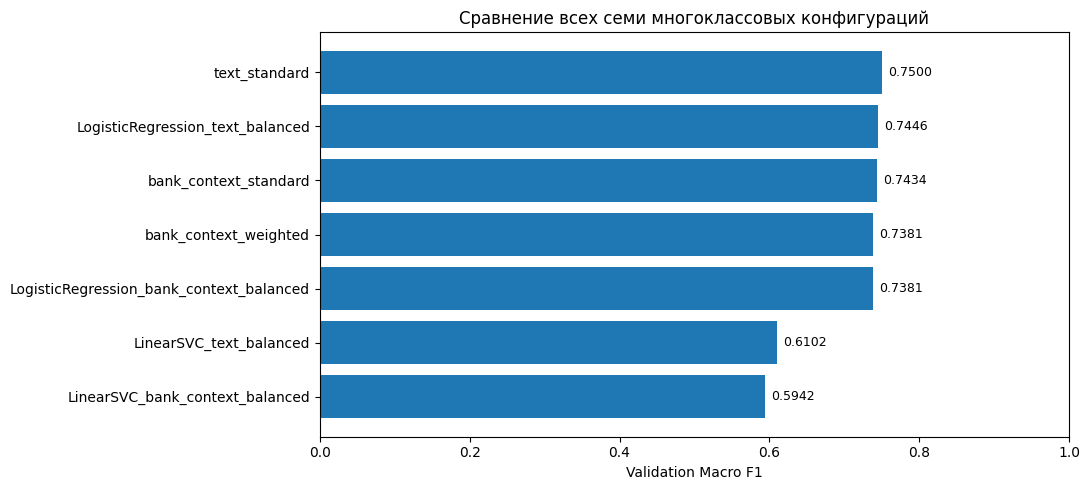

In [4]:
base_view = base.copy(); base_view['Семейство']='Классический ML'
dl_view = dl.copy(); dl_view['Семейство']='Deep Learning'
combined = pd.concat([base_view, dl_view], ignore_index=True, sort=False)
combined = combined.sort_values('macro_f1', ascending=False).reset_index(drop=True)
cols = ['Семейство','name','macro_f1','risk_macro_f1','macro_precision','macro_recall','accuracy']
display(combined[cols].rename(columns={
 'name':'Конфигурация','macro_f1':'Macro F1','risk_macro_f1':'Risk Macro F1',
 'macro_precision':'Macro Precision','macro_recall':'Macro Recall','accuracy':'Accuracy'
}).round(4))

fig, ax = plt.subplots(figsize=(11,5))
plot_data = combined.sort_values('macro_f1')
ax.barh(plot_data['name'], plot_data['macro_f1'])
ax.set_xlim(0, 1); ax.set_xlabel('Validation Macro F1')
ax.set_title('Сравнение всех семи многоклассовых конфигураций')
for i, v in enumerate(plot_data['macro_f1']): ax.text(v+0.008, i, f'{v:.4f}', va='center', fontsize=9)
fig.tight_layout(); plt.show()

## 4. Лучшие представители классического ML и Deep Learning

Победитель выбирается по `validation_macro_f1` внутри каждого семейства. Разница между двумя победителями показывает результат именно для данного валидационного разбиения, а не доказанную устойчивую закономерность.

,Модель,Семейство,Macro F1,Risk Macro F1,Accuracy
0,LogisticRegression_text_balanced,Классический ML,0.7446,0.6642,0.9735
1,text_standard,Deep Learning,0.7500,0.6718,0.9709


Разница mDeBERTa − лучший baseline: +0.005380 Macro F1 (+0.538 процентного пункта шкалы 0–100).
Выбранная конфигурация mDeBERTa: text_standard


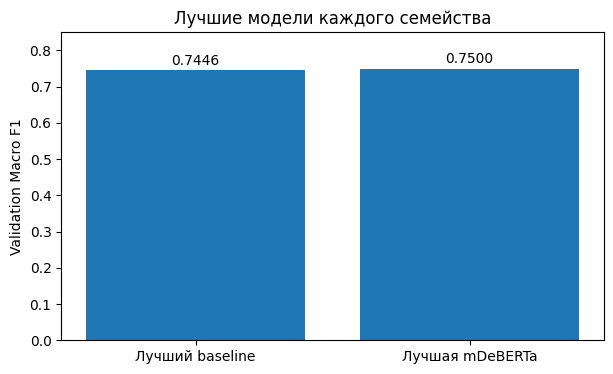

In [5]:
best_baseline = base.sort_values(['macro_f1','risk_macro_f1'],ascending=False).iloc[0]
best_dl = dl.sort_values(['macro_f1','risk_macro_f1'],ascending=False).iloc[0]
assert selection['name'] == best_dl['name']
assert np.isclose(selection['validation']['macro_f1'],best_dl['macro_f1'],rtol=0,atol=1e-12)
comparison = pd.DataFrame([
    {'Модель':best_baseline['name'],'Семейство':'Классический ML',
     'Macro F1':best_baseline['macro_f1'],'Risk Macro F1':best_baseline['risk_macro_f1'],
     'Accuracy':best_baseline['accuracy']},
    {'Модель':best_dl['name'],'Семейство':'Deep Learning',
     'Macro F1':best_dl['macro_f1'],'Risk Macro F1':best_dl['risk_macro_f1'],
     'Accuracy':best_dl['accuracy']}
])
display(comparison.round(4))
delta = float(best_dl['macro_f1'] - best_baseline['macro_f1'])
print(f'Разница mDeBERTa − лучший baseline: {delta:+.6f} Macro F1 ({delta*100:+.3f} процентного пункта шкалы 0–100).')
print('Выбранная конфигурация mDeBERTa:',selection['name'])

fig, ax=plt.subplots(figsize=(7,4))
ax.bar(['Лучший baseline','Лучшая mDeBERTa'], [best_baseline['macro_f1'],best_dl['macro_f1']])
ax.set_ylim(0, 0.85); ax.set_ylabel('Validation Macro F1')
ax.set_title('Лучшие модели каждого семейства')
for i,v in enumerate([best_baseline['macro_f1'],best_dl['macro_f1']]):ax.text(i,v+0.015,f'{v:.4f}',ha='center')
plt.show()

## 5. Качество по категориям риска

Разница по отдельным классам показывает, **за счёт чего** изменилась итоговая Macro F1. Особенно осторожно нужно интерпретировать `regulatory_risk`: на validation имеется только семь размеченных примеров.

,Класс,Logistic Regression / лучший baseline,mDeBERTa / лучшая,Разница DL − baseline
0,Нет риска,0.9861,0.9847,-0.0014
1,Киберриск,0.7895,0.7500,-0.0395
2,Операционный риск,0.7586,0.7200,-0.0386
3,Регуляторный риск,0.4444,0.5455,0.1010


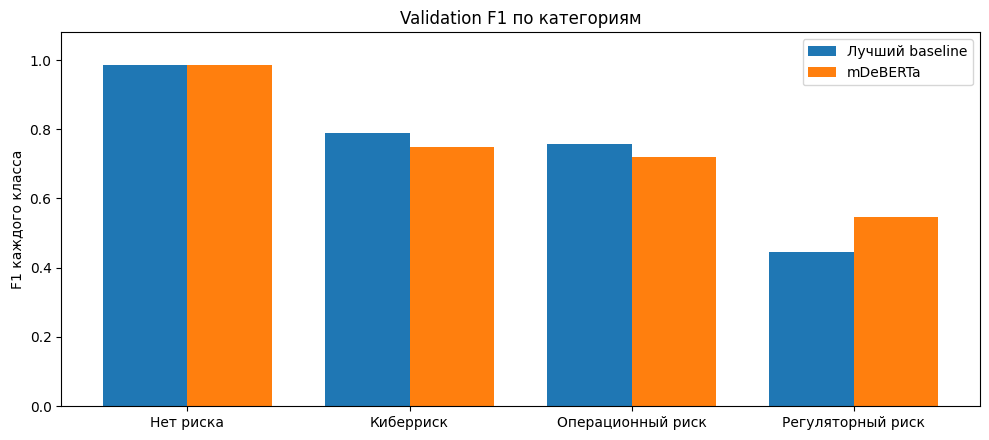

In [6]:
class_cols = ['f1_'+c for c in CLASSES]
per_class = pd.DataFrame({
    'Класс':[LABELS[c] for c in CLASSES],
    'Logistic Regression / лучший baseline':[float(best_baseline[col]) for col in class_cols],
    'mDeBERTa / лучшая':[float(best_dl[col]) for col in class_cols]})
per_class['Разница DL − baseline']=(per_class['mDeBERTa / лучшая']-
                                  per_class['Logistic Regression / лучший baseline'])
display(per_class.round(4))
x=np.arange(len(CLASSES));width=.38
fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(x-width/2, per_class['Logistic Regression / лучший baseline'],width,label='Лучший baseline')
ax.bar(x+width/2, per_class['mDeBERTa / лучшая'],width,label='mDeBERTa')
ax.set_xticks(x, per_class['Класс']);ax.set_ylim(0,1.08)
ax.set_ylabel('F1 каждого класса');ax.set_title('Validation F1 по категориям')
ax.legend();fig.tight_layout();plt.show()

## 6. Независимый пересчёт метрик лучшей mDeBERTa по предсказаниям

В `valid_predictions.csv` находятся **755 реальных прогнозов** и логиты четырёх классов. Пересчитанные метрики сверяются с сохранёнными агрегатами. Для остальных двух запусков mDeBERTa пообъектных прогнозов в локальном комплекте нет. Прогнозы четырёх классических конфигураций доступны в каталоге baseline; этот раздел пересчитывает только результат выбранной mDeBERTa.

In [7]:
valid = df[df['split']=='valid'][['sample_id','risk_type_4cls','title','text_fragment']].copy()
assert len(pred)==len(valid)==755
assert pred['sample_id'].is_unique
assert set(pred['sample_id'])==set(valid['sample_id'])
check = pred.merge(valid,on='sample_id',how='inner',validate='one_to_one',suffixes=('_saved','_dataset'))
assert (check['risk_type_4cls_saved']==check['risk_type_4cls_dataset']).all()
assert set(pred['prediction']) <= set(CLASSES)
logits = pred[['logit_'+c for c in CLASSES]].to_numpy()
assert (np.array(CLASSES)[logits.argmax(axis=1)] == pred['prediction'].to_numpy()).all()

actual=pred['risk_type_4cls']; predicted=pred['prediction']
macro_f1 = f1_score(actual,predicted,labels=CLASSES,average='macro',zero_division=0)
risk_macro_f1 = f1_score(actual,predicted,labels=CLASSES[1:],average='macro',zero_division=0)
assert np.isclose(macro_f1,best_dl['macro_f1'],atol=1e-10)
assert np.isclose(risk_macro_f1,best_dl['risk_macro_f1'],atol=1e-10)
assert np.isclose(accuracy_score(actual,predicted),best_dl['accuracy'],atol=1e-10)
print(f'Пересчитано: Macro F1 = {macro_f1:.6f}, Risk Macro F1 = {risk_macro_f1:.6f}, Accuracy = {accuracy_score(actual,predicted):.6f}')
report = pd.DataFrame(classification_report(actual,predicted,labels=CLASSES,
                                         output_dict=True,zero_division=0)).T
report.index=[LABELS.get(i,i) for i in report.index]
display(report.round(4))

Пересчитано: Macro F1 = 0.750028, Risk Macro F1 = 0.671818, Accuracy = 0.970861


,precision,recall,f1-score,support
Нет риска,0.9819,0.9874,0.9847,715.0000
Киберриск,0.7500,0.7500,0.7500,20.0000
Операционный риск,0.7500,0.6923,0.7200,13.0000
Регуляторный риск,0.7500,0.4286,0.5455,7.0000
accuracy,0.9709,0.9709,0.9709,0.9709
macro avg,0.8080,0.7146,0.7500,755.0000
weighted avg,0.9696,0.9709,0.9698,755.0000


## 7. Матрица ошибок и разбор ложных предупреждений

Строки матрицы — истинные метки, столбцы — предсказанные. Особое внимание: ложные предупреждения (`no_risk` → любой риск) и пропущенные риски (любой риск → `no_risk`). Эти величины полезны для оценки практического сценария мониторинга.

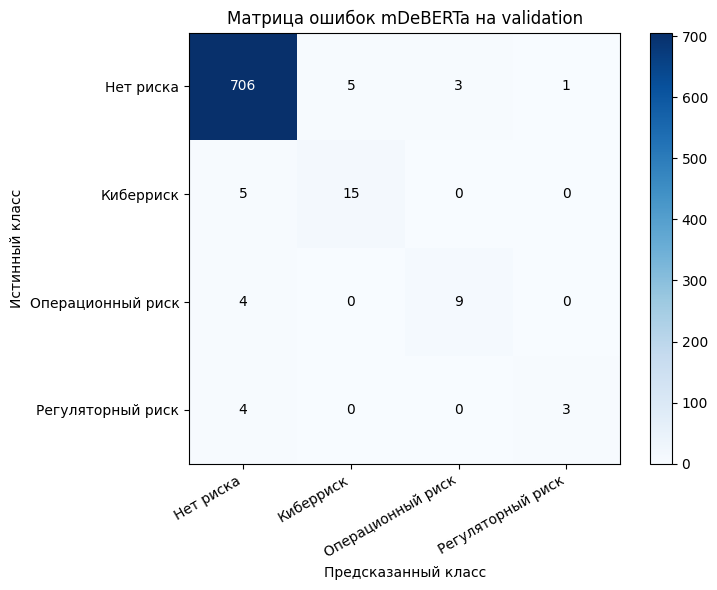

Ложные предупреждения (нет риска → риск): 9
Пропущенные риски (риск → нет риска): 13
Ошибки между типами риска: 0
Всего ошибок: 22


In [8]:
cm=confusion_matrix(actual,predicted,labels=CLASSES)
fig, ax = plt.subplots(figsize=(8.5,6))
im=ax.imshow(cm,cmap='Blues')
ax.set_xticks(range(4),[LABELS[c] for c in CLASSES],rotation=30,ha='right')
ax.set_yticks(range(4),[LABELS[c] for c in CLASSES]);ax.set_xlabel('Предсказанный класс');ax.set_ylabel('Истинный класс')
ax.set_title('Матрица ошибок mDeBERTa на validation')
for (i,j),v in np.ndenumerate(cm):
    ax.text(j,i,str(v),ha='center',va='center',color='white' if v>cm.max()/2 else 'black')
fig.colorbar(im,ax=ax,fraction=.046,pad=.04);fig.tight_layout();plt.show()
false_alerts=int(cm[0,1:].sum()); missed_risks=int(cm[1:,0].sum()); cross_risk_errors=int(cm[1:,1:].sum()-np.trace(cm[1:,1:]))
print('Ложные предупреждения (нет риска → риск):',false_alerts)
print('Пропущенные риски (риск → нет риска):',missed_risks)
print('Ошибки между типами риска:',cross_risk_errors)
print('Всего ошибок:',int((actual!=predicted).sum()))

## 8. Примеры ошибок модели

Качественный разбор включает несколько примеров каждого типа ошибок на validation. Для краткости приведены заголовки новостей.

In [9]:
errors = check[check['risk_type_4cls_saved']!=check['prediction']].copy()
errors['Тип ошибки'] = np.select([
    (errors['risk_type_4cls_saved']=='no_risk') & (errors['prediction']!='no_risk'),
    (errors['risk_type_4cls_saved']!='no_risk') & (errors['prediction']=='no_risk')],
    ['Ложное предупреждение','Пропущенный риск'],default='Перепутаны типы риска')
errors['Истинная метка']=errors['risk_type_4cls_saved'].map(LABELS)
errors['Прогноз']=errors['prediction'].map(LABELS)
errors['Заголовок']=errors['title'].fillna('').astype(str).str.slice(0,135)
examples = errors.groupby('Тип ошибки',sort=False).head(5)
display(examples[['sample_id','Тип ошибки','Истинная метка','Прогноз','Заголовок']].reset_index(drop=True))

,sample_id,Тип ошибки,Истинная метка,Прогноз,Заголовок
0,ml_nat5_final_000050,Пропущенный риск,Киберриск,Нет риска,"Кассир Сбербанка, похитившая у 82-летнего мужч..."
1,ml_nat5_final_000135,Ложное предупреждение,Нет риска,Киберриск,Изображают жертву: Мошенники изобрели новый сп...
2,ml_nat5_final_000202,Пропущенный риск,Регуляторный риск,Нет риска,Дворкович: власти договариваются с Китаем о фи...
3,ml_nat5_final_000236,Ложное предупреждение,Нет риска,Регуляторный риск,Европейский суд общей юрисдикции подтвердил по...
4,ml_nat5_final_000237,Пропущенный риск,Операционный риск,Нет риска,Глава Сбербанка отчитался о «косяках»
5,ml_nat5_final_000264,Пропущенный риск,Киберриск,Нет риска,Кто и как (на самом деле) крадет персональные ...
6,ml_nat5_final_000321,Ложное предупреждение,Нет риска,Операционный риск,Сбербанк откажется от авторизации клиентских о...
7,ml_nat5_final_000366,Ложное предупреждение,Нет риска,Операционный риск,Работа Сбербанка восстановлена после массового...
8,ml_nat5_final_000375,Пропущенный риск,Киберриск,Нет риска,"Сотрудница ""Сбербанка"", похитившая 500 тыс. ру..."
9,ml_nat5_final_000489,Ложное предупреждение,Нет риска,Киберриск,В Омске возбуждено уголовное дело в отношении ...


## 9. Проверка устойчивости Deep Learning к random seed

Дополнительно обучались две копии конфигурации `text_standard` с `seed=123` и `seed=2026`. Исходный `seed=42` повторно не обучался. **Менялся только random seed**, данные и основная конфигурация оставались прежними.

Повторные seed используются для **оценки чувствительности результата**, а не для выбора наиболее удачного из трёх запусков. Для финального test модель `text_standard`, seed 42, остаётся зафиксированной в `selection.json`.

,seed,macro_f1,risk_macro_f1,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
0,42,0.7500,0.6718,0.7500,0.7200,0.5455
1,123,0.7338,0.6499,0.7805,0.7692,0.4000
2,2026,0.7565,0.6793,0.9268,0.6667,0.4444


Среднее Macro F1: 0.7468; стандартное отклонение: 0.0117.
Выше Logistic Regression: 2 из 3 запусков.


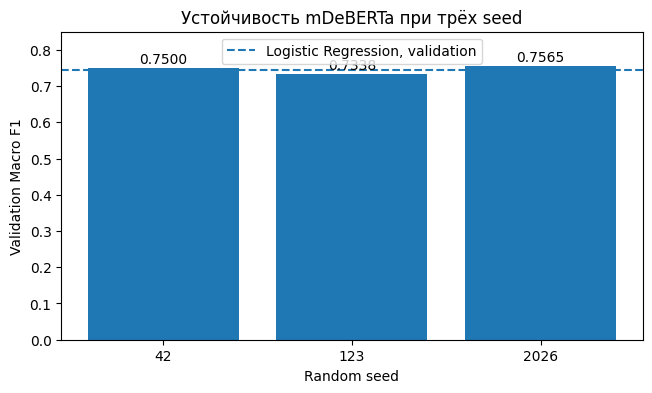

In [10]:
stability_dir = ROOT / 'results' / 'multiclass' / 'stability'
seed_table = pd.read_csv(stability_dir / 'seed_stability.csv').sort_values('seed')
seed_summary = json.loads((stability_dir / 'seed_stability_summary.json').read_text(encoding='utf-8'))
assert set(seed_table['seed']) == {42, 123, 2026}
assert (seed_table['dataset_sha256'] == dataset_sha).all()
assert seed_summary['selection_policy'] == 'original seed 42 remains frozen; no seed selected by these repeats'
assert not seed_summary['test_evaluated']
assert np.isclose(seed_table['macro_f1'].mean(), seed_summary['mean_macro_f1'])
assert np.isclose(seed_table['macro_f1'].std(ddof=1), seed_summary['sample_std_macro_f1'])
assert np.isclose(seed_table.loc[seed_table.seed==42, 'macro_f1'].iloc[0], best_dl['macro_f1'])
assert np.isclose(seed_summary['baseline_validation_macro_f1'], best_baseline['macro_f1'])
display(seed_table[['seed', 'macro_f1', 'risk_macro_f1','f1_cyber_risk','f1_operational_risk','f1_regulatory_risk']].round(4))
print(f"Среднее Macro F1: {seed_summary['mean_macro_f1']:.4f}; стандартное отклонение: {seed_summary['sample_std_macro_f1']:.4f}.")
print(f"Выше Logistic Regression: {seed_summary['seeds_above_baseline']} из {seed_summary['num_available_seeds']} запусков.")
fig, ax = plt.subplots(figsize=(7.5,4))
ax.bar([str(x) for x in seed_table['seed']], seed_table['macro_f1'])
ax.axhline(best_baseline['macro_f1'],ls='--',label='Logistic Regression, validation')
ax.set_ylim(0,0.85);ax.set_xlabel('Random seed');ax.set_ylabel('Validation Macro F1')
ax.set_title('Устойчивость mDeBERTa при трёх seed');ax.legend()
for i, v in enumerate(seed_table['macro_f1']): ax.text(i,v+0.012,f'{v:.4f}',ha='center')
plt.show()

**Интерпретация.** Средний Macro F1 mDeBERTa составляет **0,7468** (выборочное стандартное отклонение **0,0117**), против **0,7446** у лучшего baseline. Два запуска из трёх превышают baseline, один — уступает ему. Разница мала и недостаточна, чтобы утверждать устойчивое превосходство Deep Learning. В частности, F1 для редкого регуляторного риска заметно меняется между seed.

## 10. Выводы и ограничения

На validation основная mDeBERTa получила Macro F1 = 0,7500, Logistic Regression — 0,7446. Разница 0,0054 невелика; в редком регуляторном классе всего семь наблюдений. Среднее по seed 42, 123 и 2026 равно 0,7468, выборочное стандартное отклонение — 0,0117. Эти результаты не устанавливают устойчивого превосходства нейросети.

Этот отчёт сравнивает validation; окончательная оценка приведена отдельно в ноутбуке 11. Она уже выполнена для исходных конфигураций: test Macro F1 составляет 0,8206 у Logistic Regression и 0,7329 у mDeBERTa seed 42. Поэтому в дополнительной задаче определения категории риска предпочтительна Logistic Regression. Seed 2026 не использовался для замены основной модели после просмотра test.

Результат дополняет основную бинарную часть, где предпочтение mDeBERTa связано с Precision предупреждений. Macro F1 четырёх классов и бинарный F1 характеризуют разные задачи.